# 06 · Trust for honest regulars, and are targeted checks worth colleague time?

Two ideas from the outline, tested on the rescan game from week 5–6:

1. **Nectar-linked trust.** Honest regulars who pass full rescans should be checked less.
   Because trust changes who is rescanned, and rescans build trust, it is played over four rescan
   cycles of the test period: each cycle's rescans (drawn at the policy's probabilities) update
   trust for the next, and shoppers respond to the probabilities they face. Colleague time stays
   at today's level in every cycle.
2. **Targeted checks.** Week 4's check lists find honest mistakes with fewer units counted than a
   random partial check. Should some colleague time go to them instead of full rescans? And could
   an in-app "did you forget...?" prompt fix mistakes at no colleague time?

Every arm uses the same random numbers for who is rescanned and what a rescan finds, so arms
differ only by their rules.

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from smartshop.basket.data import TEST_DAYS, prepare
from smartshop.basket.model import MODEL_PATH as BASKET_PATH
from smartshop.policy.game import build_game, responses, today_hours
from smartshop.policy.search import make_policy, recalibrate
from smartshop.policy.targeted import band_yields, prompt_reach
from smartshop.policy.trust import RECOMMENDED_TRUST, TrustRule, history_events, multipliers, run_cycles
from smartshop.risk.model import MODEL_PATH, load_features
from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, money, pct, save, set_style, subtitle
from smartshop.warehouse import connect

set_style()
con = connect()
prepare(con)
base = load_features(con)
bundle = joblib.load(MODEL_PATH)
params = json.load(open('../models/policy.json'))['recommended']
g = build_game(con, base, bundle['model'], bundle['features'], TEST_DAYS)
events = history_events(con, TEST_DAYS[0])
demo = con.sql('SELECT * FROM staging.stg_member_demographics').df()
print(f'{len(g):,} test sessions; recommended policy: {params}')

47,314 test sessions; recommended policy: {'kind': 'smooth', 'floor': 0.02, 'cap': 0.5, 'tau': 0.05, 't': 0.5832778662443161}


## 1. The trust rule

Simple enough to tell a shopper:

- each **clean full rescan** in the last year lowers your rescan chance by 25%, up to 75% off;
- a find bigger than a **small slip** (one item under \$10, corrected on the spot) resets it.
  Honest shoppers with big baskets make slips often (week 3), so a slip must not wipe out trust;
- the **2% random floor always applies**: nobody is ever beyond a check.

Variants tested: no trust; any find resets; slips allowed (25% per clean rescan, up to 50% or 75%
off); and trust that also counts clean *partial* checks.

In [2]:
start = multipliers(events, g.sessions.member_id.unique(), TEST_DAYS[0], RECOMMENDED_TRUST)
mem = con.sql('SELECT member_id, gt_type FROM sim_truth.members').df().set_index('member_id').gt_type
thief = mem.reindex(start.index).isin(['opportunist', 'deliberate', 'adaptive'])
pd.Series({
    'members with any trust at the start of the test period': int((start < 1).sum()),
    'share of members': (start < 1).mean(),
    'full rescans per member before the test period': (events.kind == 'full').sum() / g.sessions.member_id.nunique(),
    'trusted members who are thieves': thief[start < 1].mean(),
    'thieves among all members': thief.mean(),
}).round(3)

members with any trust at the start of the test period    578.000
share of members                                            0.242
full rescans per member before the test period              0.387
trusted members who are thieves                             0.119
thieves among all members                                   0.142
dtype: float64

In [3]:
rules = {
    'No trust': TrustRule(enabled=False),
    'Any find resets': TrustRule(slip_units=0),
    'Slips allowed, up to 50% off': TrustRule(),
    'Slips allowed, up to 75% off (recommended)': RECOMMENDED_TRUST,
    'Partial checks count too': TrustRule(count_partial=True, max_discount=0.75),
}
rows = []
for name, rule in rules.items():
    for seed in range(3):
        cyc, real = run_cycles(g, events, params, rule, seed=seed)
        honest = real[real.honest]
        stops = honest.groupby('member_id').p.sum()  # expected stops per honest member
        hm = honest.merge(demo, on='member_id', how='left')
        ratio = {}
        for col in ['age_group', 'household_size', 'income_level']:
            d = hm.dropna(subset=[col])
            r = d.groupby(col).agg(rate=('p', 'mean'), n=('p', 'size'))
            r = r[r.n >= 200]
            ratio[f'honest-stop ratio: {col}'] = r.rate.min() / r.rate.max()
        rows.append({'rule': name, 'loss remaining': cyc.loss_remaining.sum(),
                     'recovered': cyc.recovered.sum(), 'honest stops': cyc.honest_stops.sum(),
                     'honest members stopped 3+ times': (stops >= 3).sum(),
                     'members trusted (last cycle)': cyc.members_trusted.iloc[-1],
                     "thieves' share of the trust discount": cyc.trust_discount_to_thieves.mean(),
                     'adaptive sessions stealing': cyc.adaptive_stealing.mean(), **ratio})
trust_table = pd.DataFrame(rows).groupby('rule', sort=False).mean()
trust_table.round(3)

,loss remaining,recovered,honest stops,honest members stopped 3+ times,members trusted (last cycle),thieves' share of the trust discount,adaptive sessions stealing,honest-stop ratio: age_group,honest-stop ratio: household_size,honest-stop ratio: income_level
rule,,,,,,,,,,
No trust,36824.686,6506.769,1664.498,80.000,0.000,NaN,0.776,0.591,0.630,0.541
Any find resets,36791.313,6520.464,1675.471,74.333,647.333,0.090,0.776,0.587,0.627,0.542
"Slips allowed, up to 50% off",36825.430,6586.163,1680.528,75.667,843.667,0.101,0.775,0.609,0.624,0.555
"Slips allowed, up to 75% off (recommended)",36824.874,6621.970,1681.831,70.667,848.000,0.098,0.775,0.618,0.630,0.567
Partial checks count too,37138.690,6344.570,1742.531,75.333,1378.333,0.113,0.770,0.650,0.586,0.533


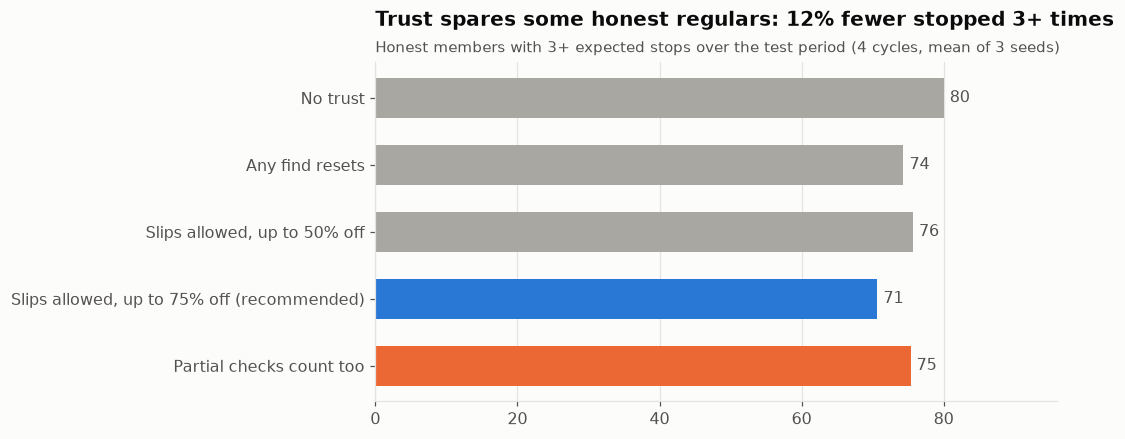

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
t = trust_table.iloc[::-1]
colors = [BLUE if 'recommended' in n else (ORANGE if 'Partial' in n else GREY) for n in t.index]
bars = ax.barh(t.index, t['honest members stopped 3+ times'], color=colors, height=0.6)
ax.bar_label(bars, labels=[f'{v:.0f}' for v in t['honest members stopped 3+ times']], padding=4, color=TEXT_2)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_xlim(0, t['honest members stopped 3+ times'].max() * 1.2)
base_n = trust_table.loc['No trust', 'honest members stopped 3+ times']
rec_n = trust_table.loc['Slips allowed, up to 75% off (recommended)', 'honest members stopped 3+ times']
ax.set_title(f'Trust spares some honest regulars: {1 - rec_n / base_n:.0%} fewer stopped 3+ times')
subtitle(ax, 'Honest members with 3+ expected stops over the test period (4 cycles, mean of 3 seeds)')
save(fig, '15_trust_repeat_stops')
fig

**What trust does, and does not do.** Colleague time is fixed, so rescans saved on trusted members
are spent on others: total honest stops barely move. What trust changes is **who** is stopped
repeatedly: fewer honest regulars are stopped again and again, and recovery edges up because
rescans move from proven-clean members to unproven ones. Thieves earn less than their share of the
discount (they are 14% of members), because a full rescan finds what they skip.

The effect is modest because trust needs evidence: under today's rescans a member has well under
one full rescan in the history, so most start with no trust and earn it slowly.

**Why partial checks must not count.** A partial check rarely sees concealed items (week 3), so a
thief can pass it. Counting partial checks hands trust to far more members, thieves included, and
costs loss on every measure.

## 2. Targeted checks against full rescans, per colleague-minute

At three risk bands under the recommended policy: the sessions it flags, the ones just below its
threshold (where it decides what to do with spare time), and everyone else.

In [5]:
cfg = g.cfg
pol = make_policy(recalibrate(g, params, today_hours(g)))
choice = responses(g, pol)
cols_i = np.arange(len(g))
s = g.sessions.assign(score=g.matrix('score')[choice, cols_i],
                      full_find=g.matrix('full_find')[choice, cols_i],
                      units=g.matrix('true_units')[choice, cols_i])
s['p'] = pol(s.score.to_numpy())
s['full_cost_min'] = (cfg.rescan_fixed_seconds + cfg.full_seconds_per_unit * s.units) / 60
s['rank'] = s.score.rank(ascending=False, pct=True)
flagged = s[s.p > 0.4]
edge = flagged['rank'].max()
bands = {
    'Flagged by the policy': flagged.sample(min(3000, len(flagged)), random_state=0),
    'Just below its threshold (next 10%)': s[(s.p < 0.4) & (s['rank'] <= edge + 0.10)],
    'Everyone else': s[(s.p < 0.4) & (s['rank'] > edge + 0.10)].sample(4000, random_state=0),
}
basket_model = joblib.load(BASKET_PATH)
yields = band_yields(con, basket_model, bands, cfg)
yields.round(3)

,sessions,full rescan: $ per minute,targeted check: $ per minute,full rescan: minutes,targeted check: minutes
band,,,,,
Flagged by the policy,1638,1.196,0.320,5.660,0.962
Just below its threshold (next 10%),4731,0.586,0.212,3.975,0.965
Everyone else,4000,0.262,0.066,1.672,0.960


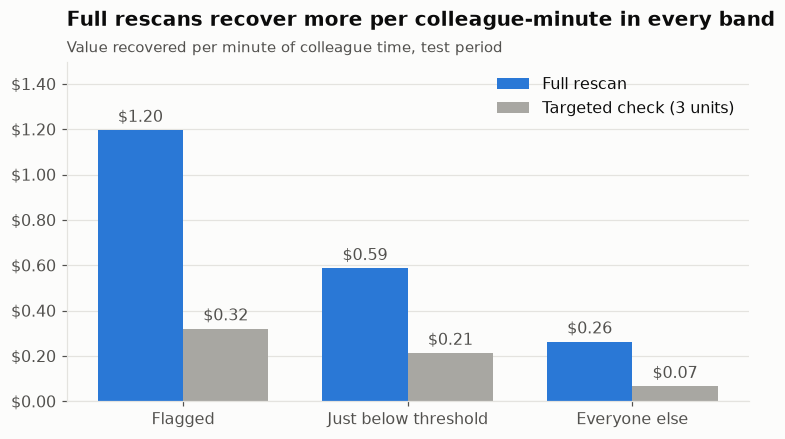

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(yields))
w = 0.38
b1 = ax.bar(x - w / 2, yields['full rescan: $ per minute'], w, color=BLUE, label='Full rescan')
b2 = ax.bar(x + w / 2, yields['targeted check: $ per minute'], w, color=GREY, label='Targeted check (3 units)')
for b in (b1, b2):
    ax.bar_label(b, labels=[f'${v:.2f}' for v in b.datavalues], padding=3, color=TEXT_2)
ax.set_xticks(x, ['Flagged', 'Just below threshold', 'Everyone else'])
ax.yaxis.set_major_formatter(money(2))
ax.set_ylim(0, yields['full rescan: $ per minute'].max() * 1.25)
ax.set_title('Full rescans recover more per colleague-minute in every band')
subtitle(ax, 'Value recovered per minute of colleague time, test period')
ax.legend(loc='upper right')
save(fig, '16_targeted_vs_full')
fig

Full rescans recover several times more per minute than targeted checks, at every band. A
targeted check is quicker, but it finds only honest mistakes in a few product types and rarely
the concealed items that carry most of the loss. Moving colleague time from full rescans to
targeted checks would lose money.

## 3. An in-app prompt instead: "did you forget...?"

No colleague time, but every prompt interrupts a shopper. Asked about the single product type
the basket model is most sure is missing, on a random sample of test sessions:

In [7]:
sample_ids = g.sessions.basket_id.sample(8000, random_state=0).to_numpy()
prompts = prompt_reach(con, basket_model, sample_ids)
prompts.round(3)

,shoppers asked,prompts that are right,mistake value pointed at
model at least this sure,,,
0.2,0.521,0.101,0.089
0.3,0.295,0.141,0.067
0.4,0.181,0.193,0.055
0.5,0.128,0.235,0.047


Most prompts would be wrong (three or four shoppers bothered for every useful prompt) and, even
if every right one were acted on, they would reach only a small share of the value missed by
mistake. Not worth the interruption.

## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | Trust (clean full rescans, slips allowed, up to 75% off) leaves total honest stops and loss about unchanged but spares repeat stops of honest regulars and edges recovery up | Added to the recommended policy as a fairness refinement, not a loss lever |
| 2 | Thieves get less than their share of the trust discount, because full rescans catch what they skip | Trust built on full rescans is hard to game |
| 3 | Counting clean *partial* checks spreads trust to many more members, thieves included, and is worse on loss and honest stops | Never build trust on checks that cannot see concealed items |
| 4 | Full rescans recover several times more per colleague-minute than targeted checks at every risk band | Targeted checks do not earn colleague time; the basket model's value is as a risk feature and a "look here first" hint inside a full rescan |
| 5 | An in-app "did you forget...?" prompt would usually be wrong and reach little | Not recommended |

**Recommended policy from here on:** the week 6 randomised policy (2% random floor, cap 0.5) with
the trust rule above, stored in `models/policy.json`.